# 04 · Predicting bikes available one hour ahead

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code: turning the change log into an hourly supervised dataset, baselines, gradient-boosting search, ablations, test evaluation, unseen-station check, final model and saved bundles.
- Chose the features, the time split (train < 1 May 2023, validation May 2023, test 1 Jun – 15 Jul 2023), the model family and the selection metric (RMSE).

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- The official evaluation set was not available, so it has not been seen or used.
- No neural/sequence models. No LightGBM/XGBoost (not installed); only scikit-learn.
- No trip-based features, because the evaluation set will probably contain only status data.
- No prediction intervals or probabilistic forecasts.

_Team notes:_

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.width", 200)
VAL_START, TEST_START = pd.Timestamp("2023-05-01"), pd.Timestamp("2023-06-01")
TRAIN_SAMPLE = 3_000_000   # model selection / ablations; refits use all rows
RNG = np.random.default_rng(0)

status = pd.read_csv(bc.DATA_DIR / "stations_status.csv")
stations = pd.read_csv(bc.DATA_DIR / "stations.csv")
cities = pd.read_csv(bc.DATA_DIR / "cities.csv")
clusters = bc.load_clean("station_clusters")
wl = bc.weather_lookup(pd.read_csv(bc.EXTERNAL_DIR / "weather_hourly.csv"))


def metrics(y, p):
    return {"MAE": float(np.mean(np.abs(y - p))), "RMSE": float(np.sqrt(np.mean((y - p) ** 2)))}

## 1. From a change log to a learning problem

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Example plot of one station. Capacity estimated from data before 1 June; station × hour profile fitted on data before 1 May for model selection.
- Rows kept only when the hour is valid, the next hour is valid, and the station is not in maintenance at t or t+1h. Target = available bikes at t+1h.

**Not done by Claude**
- Hours in maintenance are not predicted at all.

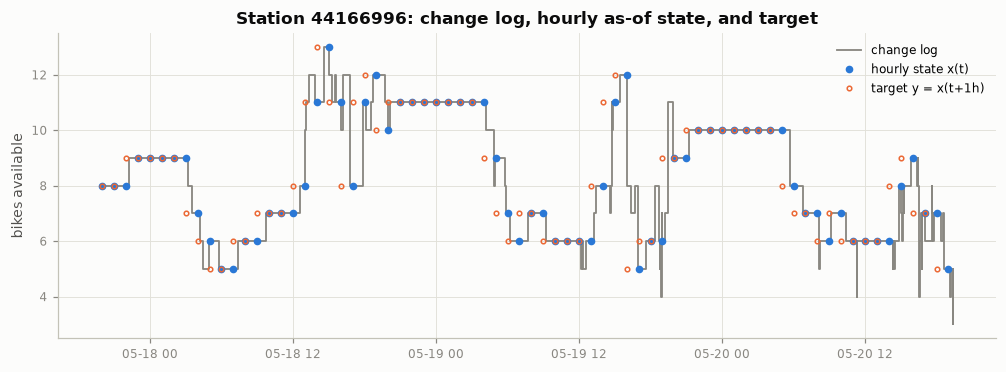

In [2]:
# one station over three days: raw records vs the hourly as-of state and the 1h-ahead target
s = bc.clean_status(status)
sid = s.station_id.value_counts().index[50]
s1 = s[(s.station_id == sid)]
t0 = s1.time.quantile(0.6)
win = s1[(s1.time >= t0) & (s1.time < t0 + 3 * 86400)]
g1 = bc.hourly_grid(s1)
g1 = g1[(g1.hour_epoch * 3600 >= t0) & (g1.hour_epoch * 3600 < t0 + 3 * 86400)]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.step(pd.to_datetime(win.time, unit="s"), win.bikes_available_to_rent, where="post", color=bc.GREY, lw=1.2, label="change log")
ax.plot(pd.to_datetime(g1.hour_epoch * 3600, unit="s"), g1.bikes_available_to_rent, "o", ms=4, color=bc.SERIES[0], label="hourly state x(t)")
ax.plot(pd.to_datetime(g1.hour_epoch * 3600, unit="s"), g1.bikes_available_to_rent.shift(-1), "o", ms=3, mfc="none", color=bc.SERIES[1], label="target y = x(t+1h)")
ax.set(title=f"Station {sid}: change log, hourly as-of state, and target", ylabel="bikes available")
ax.legend()
plt.show()

In [3]:
capacity = bc.station_capacity(bc.clean_status(status[status.time < TEST_START.timestamp()]))
t0 = time.time()
profile_train = bc.fit_station_profile(status, stations, cities, capacity, VAL_START)
d = bc.build_supervised(status, stations, cities, capacity, profile_train, clusters, wl)
print(f"{len(d):,} rows, {d.memory_usage().sum() / 1e9:.2f} GB, {time.time() - t0:.0f}s")
split = np.where(d.utc < VAL_START, "train", np.where(d.utc < TEST_START, "val", "test"))
d["split"] = split
d.groupby("split").agg(rows=("station_id", "size"), stations=("station_id", "nunique"),
                       start=("utc", "min"), end=("utc", "max")).loc[["train", "val", "test"]]

12,218,387 rows, 2.57 GB, 21s


,rows,stations,start,end
split,,,,
train,9266845,2706,2022-08-26 15:00:00,2023-04-30 23:00:00
val,834876,2121,2023-05-01 00:00:00,2023-05-31 23:00:00
test,2116666,2284,2023-06-01 00:00:00,2023-07-15 20:00:00


share of rows where availability changes within the hour: 0.104


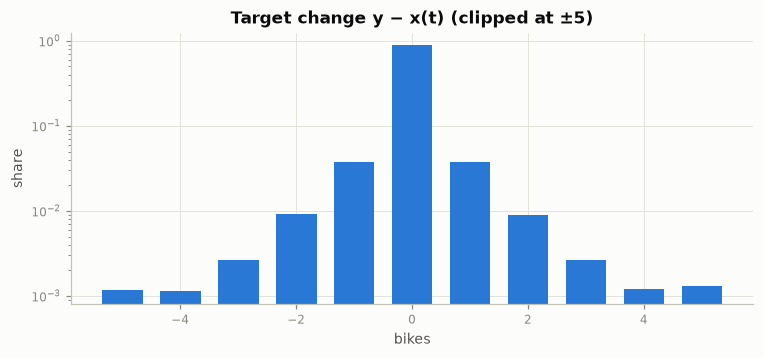

In [4]:
delta = d.target - d.bikes_available_to_rent
print("share of rows where availability changes within the hour:", (delta != 0).mean().round(3))
fig, ax = plt.subplots(figsize=(8, 3.2))
vc = delta.clip(-5, 5).value_counts(normalize=True).sort_index()
ax.bar(vc.index, vc.values, color=bc.SERIES[0], width=.7)
ax.set(title="Target change y − x(t) (clipped at ±5)", xlabel="bikes", ylabel="share", yscale="log")
plt.show()

In [5]:
FEATS = bc.FEATURES
NUM = [f for f in FEATS if f not in bc.CATEGORICAL]
tr, va, te = (d[d.split == k] for k in ["train", "val", "test"])
sub = tr.sample(min(TRAIN_SAMPLE, len(tr)), random_state=0)
print(len(sub), "training rows used for model selection")

3000000 training rows used for model selection


_Team notes:_

## 2. Baselines

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Persistence, persistence + station-hour mean change, station-hour mean level, and Ridge on the change (3M-row sample).

In [6]:
res = {}
for name, D in [("val", va), ("test", te)]:
    res[("persistence", name)] = metrics(D.target, D.bikes_available_to_rent)
    res[("persistence + station-hour mean change", name)] = metrics(D.target, D.bikes_available_to_rent + D.prof_delta.fillna(0))
    res[("station-hour mean level", name)] = metrics(D.target, D.prof_avail.fillna(D.bikes_available_to_rent))

ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))
ridge.fit(sub[NUM], sub.target - sub.bikes_available_to_rent)
for name, D in [("val", va), ("test", te)]:
    res[("ridge (Δ)", name)] = metrics(D.target, (D.bikes_available_to_rent + ridge.predict(D[NUM])).clip(lower=0))
base = pd.DataFrame(res).T.unstack()
base.round(4)

MAE            RMSE        
                                          test     val    test     val
persistence                             0.2120  0.2036  0.7138  0.7003
persistence + station-hour mean change  0.2428  0.2338  0.6959  0.6775
ridge (Δ)                               0.2624  0.2539  0.6849  0.6679
station-hour mean level                 2.1142  2.0305  3.0082  2.8803

_Team notes:_

## 3. Gradient boosting: loss and hyper-parameters (selected on May 2023)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- 5 HistGradientBoosting configurations (squared, absolute, Poisson loss) with early stopping, fitted on a 3M-row training sample and selected on May RMSE.
- The model predicts the change y − x(t); the prediction is clipped at 0 from below.

**Not done by Claude**
- No random or Bayesian search; `l2_regularization` was not tuned.
- No upper clip. A clip at 1.5 × capacity was removed after it hurt virtual stations.

In [7]:
grid = [
    dict(loss="squared_error", learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=200),
    dict(loss="squared_error", learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=200),
    dict(loss="squared_error", learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=500),
    dict(loss="absolute_error", learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=200),
    dict(loss="poisson", learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=200),
]
search = []
for params in grid:
    t0 = time.time()
    poisson = params["loss"] == "poisson"
    m = HistGradientBoostingRegressor(max_iter=400, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
                                      categorical_features="from_dtype", l2_regularization=1.0, random_state=0, **params)
    # poisson needs a non-negative target -> model the level; other losses model the change
    m.fit(sub[FEATS], sub.target if poisson else sub.target - sub.bikes_available_to_rent)
    p = m.predict(va[FEATS]) if poisson else va.bikes_available_to_rent + m.predict(va[FEATS])
    search.append({**params, "iters": m.n_iter_, **metrics(va.target, p.clip(0)), "fit_s": round(time.time() - t0)})
search = pd.DataFrame(search)
search.round(4)

,loss,learning_rate,max_leaf_nodes,min_samples_leaf,iters,MAE,RMSE,fit_s
0,squared_error,0.10,31,200,266,0.2422,0.6605,10
1,squared_error,0.10,63,200,224,0.2439,0.6608,10
2,squared_error,0.05,127,500,215,0.2453,0.6622,14
3,absolute_error,0.10,63,200,97,0.2014,0.6862,11
4,poisson,0.10,63,200,201,0.2519,0.6737,11


In [8]:
# selected on validation RMSE
BEST = search.sort_values("RMSE").iloc[0][["loss", "learning_rate", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
BEST["max_leaf_nodes"], BEST["min_samples_leaf"] = int(BEST["max_leaf_nodes"]), int(BEST["min_samples_leaf"])
BEST

{'loss': 'squared_error',
 'learning_rate': 0.1,
 'max_leaf_nodes': 31,
 'min_samples_leaf': 200}

In [9]:
def fit_hgb(D, params, max_iter=None):
    poisson = params["loss"] == "poisson"
    m = HistGradientBoostingRegressor(max_iter=max_iter or 400, early_stopping=max_iter is None, validation_fraction=0.1,
                                      n_iter_no_change=20, categorical_features="from_dtype", l2_regularization=1.0,
                                      random_state=0, **params)
    m.fit(D[FEATS], D.target if poisson else D.target - D.bikes_available_to_rent)
    return m


def predict(m, D, params):
    p = m.predict(D[FEATS]) if params["loss"] == "poisson" else D.bikes_available_to_rent + m.predict(D[FEATS])
    return np.clip(p, 0, None)

_Team notes:_

## 4. Ablations (train sample → May 2023)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Removed one feature group at a time and retrained with the same number of iterations; compared on May.

**Not done by Claude**
- Single run per ablation: no repeats or confidence intervals.

In [10]:
groups = {
    "history (lags, deltas, rolling, activity)": ["avail_lag1", "avail_lag2", "avail_lag3", "avail_lag24", "avail_lag168", "d1", "d3",
                                                  "roll24_mean", "roll24_std", "changes_1h", "changes_24h", "since_change_h"],
    "station-hour profile": ["prof_avail", "prof_delta", "prof_absdelta"],
    "weather": ["temperature_2m", "precipitation", "wind_speed_10m"],
    "calendar": ["hour", "dow", "weekend", "hour_sin", "hour_cos", "doy_sin", "doy_cos"],
    "station cluster + city": ["station_cluster_cat", "city_cat"],
}
full_m = fit_hgb(sub, BEST)
abl = {"all features": metrics(va.target, predict(full_m, va, BEST))}
for gname, cols in groups.items():
    keep = [f for f in FEATS if f not in cols]
    poisson = BEST["loss"] == "poisson"
    m = HistGradientBoostingRegressor(max_iter=full_m.n_iter_, early_stopping=False, categorical_features="from_dtype",
                                      l2_regularization=1.0, random_state=0, **BEST)
    m.fit(sub[keep], sub.target if poisson else sub.target - sub.bikes_available_to_rent)
    p = m.predict(va[keep]) if poisson else va.bikes_available_to_rent + m.predict(va[keep])
    abl[f"without {gname}"] = metrics(va.target, np.clip(p, 0, None))
abl = pd.DataFrame(abl).T
abl["ΔMAE vs all"] = abl.MAE - abl.loc["all features", "MAE"]
abl["ΔRMSE vs all"] = abl.RMSE - abl.loc["all features", "RMSE"]
abl.round(4)

,MAE,RMSE,ΔMAE vs all,ΔRMSE vs all
all features,0.2422,0.6605,0.0000,0.0000
"without history (lags, deltas, rolling, activity)",0.2444,0.6640,0.0022,0.0035
without station-hour profile,0.2389,0.6656,-0.0033,0.0051
without weather,0.2425,0.6604,0.0003,-0.0001
without calendar,0.2409,0.6609,-0.0013,0.0004
without station cluster + city,0.2429,0.6618,0.0007,0.0013


_Team notes:_

## 5. Preliminary evaluation: refit on train+val, test on 1 Jun – 15 Jul 2023

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Refit on all train+val rows with the profile recomputed on data before 1 June; absolute-loss variant for comparison.
- Test tables; hours with vs without change; precision/recall for 'empty in 1h'; MAE by hour and by cluster; RMSE by capacity band and per station; one-week plot; permutation importance (150k test sample).

**Not done by Claude**
- No statistical test of the difference against persistence.

In [11]:
# profile and capacity recomputed with everything before the test period
del d, tr, va, sub, full_m
profile_tv = bc.fit_station_profile(status, stations, cities, capacity, TEST_START)
d2 = bc.build_supervised(status, stations, cities, capacity, profile_tv, clusters, wl)
tv = d2[d2.utc < TEST_START]
te = d2[d2.utc >= TEST_START].copy()
del d2
t0 = time.time()
model_tv = fit_hgb(tv, BEST)
N_TV = len(tv)
print(f"fit on {len(tv):,} rows, {model_tv.n_iter_} iterations, {time.time() - t0:.0f}s")
te["pred"] = predict(model_tv, te, BEST)
# MAE-oriented variant: same features, absolute loss (conditional median)
mae_params = {**BEST, "loss": "absolute_error"}
model_abs = fit_hgb(tv, mae_params)
te["pred_abs"] = predict(model_abs, te, mae_params)
te["persist"] = te.bikes_available_to_rent
test_res = pd.DataFrame({
    "persistence": metrics(te.target, te.persist),
    "persistence + station-hour mean change": metrics(te.target, te.persist + te.prof_delta.fillna(0)),
    "HGB": metrics(te.target, te.pred),
    "HGB (rounded to whole bikes)": metrics(te.target, te.pred.round()),
    "HGB absolute-error loss": metrics(te.target, te.pred_abs),
}).T
test_res["MAE skill vs persistence"] = 1 - test_res.MAE / test_res.loc["persistence", "MAE"]
test_res["RMSE skill vs persistence"] = 1 - test_res.RMSE / test_res.loc["persistence", "RMSE"]
test_res.round(4)

fit on 10,101,721 rows, 400 iterations, 47s


,MAE,RMSE,MAE skill vs persistence,RMSE skill vs persistence
persistence,0.2120,0.7138,0.0000,0.0000
persistence + station-hour mean change,0.2435,0.6942,-0.1487,0.0274
HGB,0.2564,0.6748,-0.2095,0.0546
HGB (rounded to whole bikes),0.2170,0.6844,-0.0238,0.0411
HGB absolute-error loss,0.2112,0.7090,0.0036,0.0067


In [12]:
moved = te.target != te.persist
pd.DataFrame({
    "hours with a change": {"share": moved.mean(), "model MAE": metrics(te.target[moved], te.pred[moved])["MAE"],
                            "persistence MAE": metrics(te.target[moved], te.persist[moved])["MAE"]},
    "hours without change": {"share": (~moved).mean(), "model MAE": metrics(te.target[~moved], te.pred[~moved])["MAE"],
                             "persistence MAE": 0.0},
}).T.round(4)

,share,model MAE,persistence MAE
hours with a change,0.1378,1.4031,1.5382
hours without change,0.8622,0.0731,0.0000


In [13]:
# operational view: will the station be empty in one hour?
emp = te.target == 0
rows = {}
for name, flag in [("persistence (empty now)", te.persist == 0), ("model (pred < 0.5)", te.pred < 0.5),
                   ("model (pred < 1.0)", te.pred < 1.0)]:
    tp = (emp & flag).sum()
    rows[name] = {"precision": tp / flag.sum(), "recall": tp / emp.sum(), "flagged": flag.mean()}
# the interesting cases: not empty now, empty in an hour
newly = emp & (te.persist > 0)
rows["model on 'becomes empty' events (pred < 1.0)"] = {
    "precision": (newly & (te.pred < 1.0) & (te.persist > 0)).sum() / ((te.pred < 1.0) & (te.persist > 0)).sum(),
    "recall": (newly & (te.pred < 1.0)).sum() / newly.sum(), "flagged": ((te.pred < 1.0) & (te.persist > 0)).mean()}
pd.DataFrame(rows).T.round(4)

,precision,recall,flagged
persistence (empty now),0.9216,0.9220,0.1175
model (pred < 0.5),0.9405,0.8867,0.1107
model (pred < 1.0),0.6398,0.9367,0.1719
model on 'becomes empty' events (pred < 1.0),0.0527,0.3279,0.0570


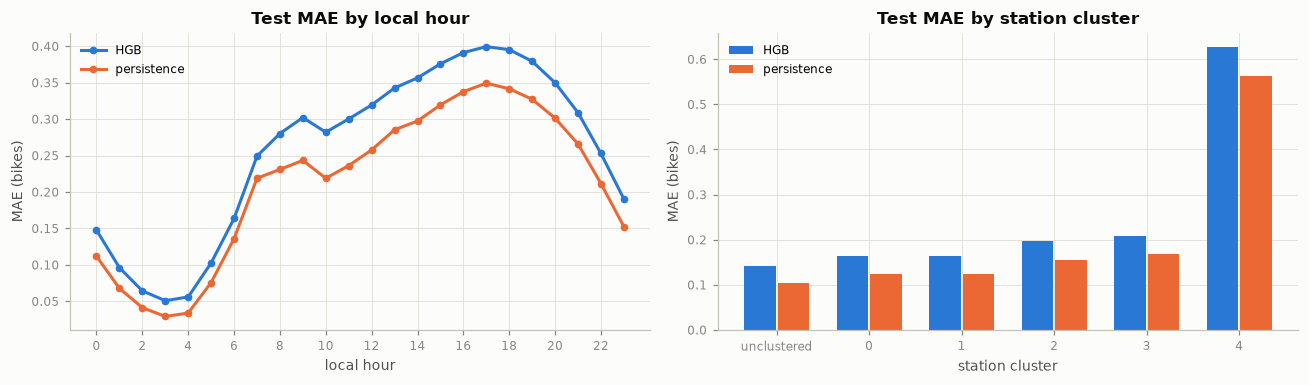

In [14]:
te["ae"], te["ae_p"] = (te.target - te.pred).abs(), (te.target - te.persist).abs()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bh = te.groupby("hour")[["ae", "ae_p"]].mean()
ax[0].plot(bh.index, bh.ae, label="HGB", marker="o", ms=4)
ax[0].plot(bh.index, bh.ae_p, label="persistence", marker="o", ms=4)
ax[0].set(title="Test MAE by local hour", xlabel="local hour", ylabel="MAE (bikes)", xticks=range(0, 24, 2))
ax[0].legend()
bc_ = te.groupby("station_cluster")[["ae", "ae_p"]].mean()
x = np.arange(len(bc_))
ax[1].bar(x - .18, bc_.ae, width=.34, label="HGB", color=bc.SERIES[0])
ax[1].bar(x + .18, bc_.ae_p, width=.34, label="persistence", color=bc.SERIES[1])
ax[1].set(title="Test MAE by station cluster", xticks=x, xticklabels=[str(c) if c >= 0 else "unclustered" for c in bc_.index],
          xlabel="station cluster", ylabel="MAE (bikes)")
ax[1].legend()
plt.tight_layout()
plt.show()

In [15]:
# error vs station size, and per-station skill distribution
te["se"], te["se_p"] = te.ae ** 2, te.ae_p ** 2
te["cap_bin"] = pd.qcut(te.capacity, 5, duplicates="drop")
cb = te.groupby("cap_bin", observed=True)[["se", "se_p"]].mean() ** 0.5
print(cb.rename(columns={"se": "RMSE model", "se_p": "RMSE persistence"}).assign(skill=lambda x: 1 - x.iloc[:, 0] / x.iloc[:, 1]).round(4))
ps = te.groupby("station_id")[["se", "se_p"]].mean() ** 0.5
ps = ps[ps.se_p > 0]
skill = 1 - ps.se / ps.se_p
print("stations where the model beats persistence (RMSE):", (skill > 0).mean().round(3), "| median skill:", skill.median().round(3))

               RMSE model  RMSE persistence   skill
cap_bin                                            
(0.999, 7.0]       0.3749            0.3812  0.0166
(7.0, 9.19]        0.4659            0.4787  0.0269
(9.19, 12.0]       0.5405            0.5566  0.0289
(12.0, 17.0]       0.7329            0.7560  0.0305
(17.0, 105.0]      1.0612            1.1539  0.0803
stations where the model beats persistence (RMSE): 0.703 | median skill: 0.01


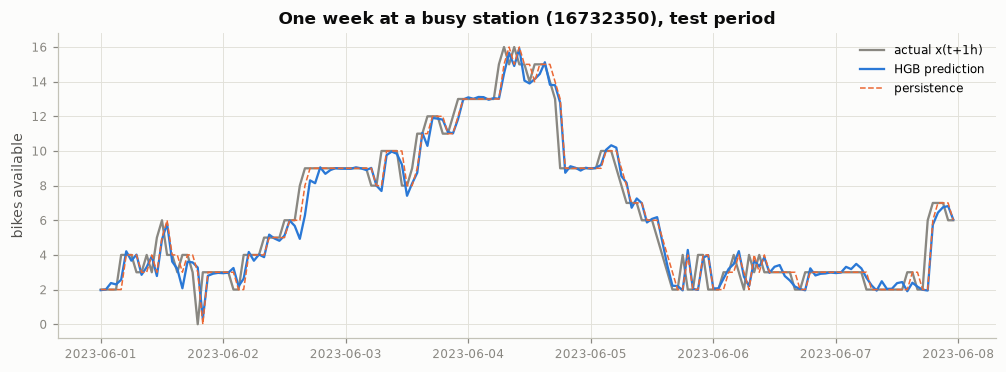

In [16]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sid = te.groupby("station_id").ae_p.mean().sort_values().index[int(.9 * te.station_id.nunique())]
x = te[te.station_id == sid].sort_values("utc").iloc[:24 * 7]
ax.plot(x.utc, x.target, color=bc.GREY, lw=1.5, label="actual x(t+1h)")
ax.plot(x.utc, x.pred, color=bc.SERIES[0], lw=1.5, label="HGB prediction")
ax.plot(x.utc, x.persist, color=bc.SERIES[1], lw=1, ls="--", label="persistence")
ax.set(title=f"One week at a busy station ({sid}), test period", ylabel="bikes available")
ax.legend()
plt.show()

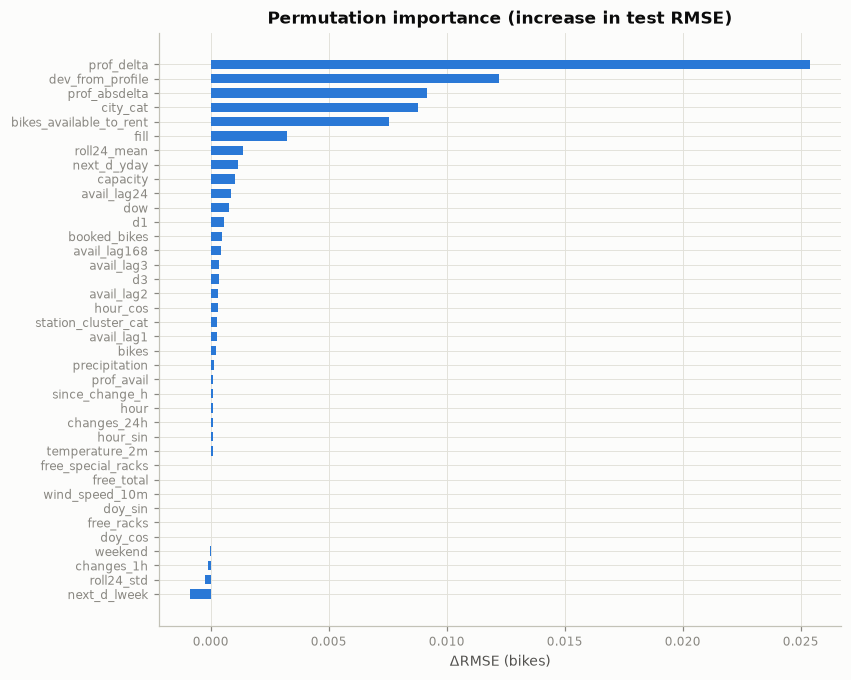

In [17]:
# permutation importance on a test sample
ps_idx = te.sample(150_000, random_state=0)
y_perm = ps_idx.target - ps_idx.bikes_available_to_rent if BEST["loss"] != "poisson" else ps_idx.target
pi = permutation_importance(model_tv, ps_idx[FEATS], y_perm, scoring="neg_root_mean_squared_error", n_repeats=3, random_state=0, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp.values, color=bc.SERIES[0], height=.65)
ax.set(title="Permutation importance (increase in test RMSE)", xlabel="ΔRMSE (bikes)")
plt.show()

_Team notes:_

## 6. Robustness: stations never seen in training

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Held out 20% of stations, retrained without them, and blanked their profile features on the test period.

**Not done by Claude**
- Held-out stations still have their station-cluster label from notebook 03, which was computed from their own pre-June data, so they are not completely unseen.

In [18]:
st_ids = tv.station_id.unique()
held = RNG.choice(st_ids, size=len(st_ids) // 5, replace=False)
tv_in = tv[~tv.station_id.isin(held)]
m_h = fit_hgb(tv_in.sample(min(TRAIN_SAMPLE, len(tv_in)), random_state=2), BEST)
te_out = te[te.station_id.isin(held)].copy()
# an unseen station has no history-based profile
te_out[["prof_avail", "prof_delta", "prof_absdelta"]] = np.nan
pd.DataFrame({
    "persistence": metrics(te_out.target, te_out.persist),
    "HGB, stations seen": metrics(te_out.target, te_out.pred),
    "HGB, stations unseen": metrics(te_out.target, predict(m_h, te_out, BEST)),
}).T.round(4)

,MAE,RMSE
persistence,0.1925,0.6508
"HGB, stations seen",0.2371,0.6279
"HGB, stations unseen",0.2099,0.6423


_Team notes:_

## 7. Final model for the evaluation set (all data up to 15 Jul 2023) and saved artifacts

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Retrained on all data up to 15 Jul 2023 with the iteration count of the test-period model.
- Saved `availability_hgb_testperiod.joblib`, `availability_hgb_final.joblib` and `metrics.json`.

**Not done by Claude**
- The final model has not been evaluated (no data after 15 Jul 2023). Its quality is assumed from the test-period model.

In [19]:
END = te.utc.max() + pd.Timedelta(hours=2)
capacity_all = bc.station_capacity(bc.clean_status(status))
profile_all = bc.fit_station_profile(status, stations, cities, capacity_all, END)
del tv, tv_in
d3 = bc.build_supervised(status, stations, cities, capacity_all, profile_all, clusters, wl)
final = fit_hgb(d3, BEST, max_iter=model_tv.n_iter_)
bc.MODEL_DIR.mkdir(exist_ok=True)
common = {"features": FEATS, "params": BEST, "clusters": clusters}
joblib.dump({**common, "model": model_tv, "capacity": capacity, "profile": profile_tv, "trained_until": str(TEST_START),
             "train_rows": N_TV}, bc.MODEL_DIR / "availability_hgb_testperiod.joblib", compress=3)
joblib.dump({**common, "model": final, "capacity": capacity_all, "profile": profile_all, "trained_until": str(END),
             "train_rows": len(d3)}, bc.MODEL_DIR / "availability_hgb_final.joblib", compress=3)
bc.save_json({"params": BEST,
              "test": {**metrics(te.target, te.pred), "persistence_MAE": metrics(te.target, te.persist)["MAE"],
                       "persistence_RMSE": metrics(te.target, te.persist)["RMSE"], "rows": len(te)},
              "test_absolute_loss": metrics(te.target, te.pred_abs),
              "validation_search": search.to_dict(orient="records")}, bc.MODEL_DIR / "metrics.json")
sorted(p.name for p in bc.MODEL_DIR.iterdir())

['availability_hgb_final.joblib',
 'availability_hgb_testperiod.joblib',
 'metrics.json',
 'predictions_demo.csv']